# Importing seqFISH+ multi-omics data (Takei 2025 cerebellum)

DNA seqFISH+ multi-omics images ~100,000 genomic loci per nucleus at 25 kb resolution
together with dozens of immunofluorescence (IF) and RNA channels, so every DNA spot carries
its own chromatin-mark signals.  In this tutorial you import such data with
`uchrom.io.read_seqfish_multiomics` and walk through how it maps onto `ChromData`: the locus
panel (`bins`), spots and traces, the 62 per-spot signals (`spot_tracks`), cells with types,
positions and a UMAP (`cells`, `cellm`), per-trace quality (`traces`) and metadata (`uns`).
You also stream the import into a store (`out=`) and open the full replicate backed from the
public U-Chrom atlas.

**Data**: Takei et al. 2025, *Nature* (doi:10.1038/s41586-025-08838-x), adult mouse
cerebellum, Zenodo [7693825](https://zenodo.org/records/7693825); locus map and cell
clustering from the authors' repository CaiGroup/dna-seqfish-plus-multi-omics.  We import the
first 47 cells of replicate 1, field of view 0: `ds.fetch("takei2025_fov0")` streams the start of
that FOV's CSV (47 whole cells, 0.27 GB) out of the Zenodo tarball and downloads the two tables
from GitHub, once.  The last section opens the whole replicate (1,799 cells, 10.9 M spots) from
the atlas over HTTP.  **Runtime**: about a minute.

In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from chromdata import ChromData
import uchrom.datasets as ds
from uchrom.io import read_seqfish_multiomics
from uchrom.io.seqfish_multiomics import IF_COLUMNS
from uchrom.emb import aggregate_tracks

plt.rcParams["figure.dpi"] = 90

OUT = Path("_out"); OUT.mkdir(exist_ok=True)   # outputs: tutorials/_out/ (ignored by git)
FOV0 = ds.fetch("takei2025_fov0")              # folder; built once from Zenodo 7693825 + the authors' GitHub
SPOTS = FOV0 / "cerebellum_rep1_pos0_cells.csv"                  # 47 whole cells of rep 1 / FOV 0
LOCI = FOV0 / "LC1-100k-09022022-mm10-25kb-meta.csv"             # 25-kb locus map (GitHub)
CLUSTERS = FOV0 / "cerebellum_mRNA_cluster_nuc_vol_filtered.csv" # per-cell clustering (GitHub)
for p in (SPOTS, LOCI, CLUSTERS):
    print(f"{p.relative_to(ds.data_dir())}  ({p.stat().st_size / 1e6:.1f} MB)")

takei2025_fov0/cerebellum_rep1_pos0_cells.csv  (272.7 MB)
takei2025_fov0/LC1-100k-09022022-mm10-25kb-meta.csv  (7.5 MB)
takei2025_fov0/cerebellum_mRNA_cluster_nuc_vol_filtered.csv  (0.3 MB)


## 1. The input files

* **Spot table** (one CSV per field of view): one row per DNA spot with `rep, fov, cellID`,
  the locus `name` (e.g. `chr7-1628`), its position (`x_um, y_um, z_um`; `x, y, z` are
  voxels), three homolog (allele) assignments of increasing recall (`dbscan_allele`,
  `dbscan_ldp_allele`, `dbscan_ldp_nbr_allele`; −1 = unassigned) and 59 z-scored signals
  measured at the spot.
* **Locus map**: `name → chrom, start, end` (+ GC content, genes) for the whole probe panel.
* **Cell clustering**: per cell `leiden` cluster, the published RNA UMAP, nuclear centroid
  (voxels) and volume, doublet flag.

In [2]:
head = pd.read_csv(SPOTS, nrows=5)
print(f"{len(head.columns)} columns:", ", ".join(head.columns[:9]), "...", ", ".join(head.columns[-8:]))
head[["rep", "fov", "cellID", "name", "chrom", "x_um", "y_um", "z_um",
      "dbscan_ldp_nbr_allele", "H3K27ac", "LaminB1", "dot_int"]]

76 columns: rep, fov, cellID, x, y, z, dot_int, name, chrom ... dbscan_allele, dbscan_ldp_allele, dbscan_ldp_nbr_allele, x_um, y_um, z_um, n_rad_score, n_per_dist(um)


,rep,fov,cellID,name,chrom,x_um,y_um,z_um,dbscan_ldp_nbr_allele,H3K27ac,LaminB1,dot_int
0,1,0,270,chr7-1628,chr7,135.735563,105.863812,1.61650,-1,-1.20850,-0.84303,832
1,1,0,270,chr1-5057,chr1,135.981733,112.468790,1.60700,-1,-1.10850,-1.19330,339
2,1,0,270,chr10-1393,chr10,131.758424,107.129991,1.60600,1,-1.06140,-0.72628,469
3,1,0,270,chr5-2621,chr5,132.623212,109.053310,1.62025,1,-0.89848,-1.02740,618
4,1,0,270,chr5-3162,chr5,132.479630,107.992513,1.59625,1,-0.53742,-0.70170,678


In [3]:
print(pd.read_csv(LOCI, nrows=3).iloc[:, :6], "\n")
pd.read_csv(CLUSTERS, nrows=3)

     name chrom    start      end   pct_gc gene
0  chr1-1  chr1  3000000  3025000  0.36568    .
1  chr1-2  chr1  3025000  3050000  0.40372    .
2  chr1-3  chr1  3050000  3075000  0.38940    . 



,fov,cellID,rep,batch,leiden,umap_1,umap_2,x,y,z,nuc_volume(um3),doublet
0,0,42,1,1,0,6.809154,10.963283,1882.598,1580.253,12.786,131.695,0
1,0,47,1,1,0,6.307696,10.393372,624.847,1731.403,13.590,163.495,0
2,0,69,1,1,0,6.173099,11.890781,1983.711,1591.343,14.482,109.238,0


## 2. Import with `read_seqfish_multiomics`

One call reads the spot CSV(s) (a path, a glob or a list — one file per FOV), resolves the
locus names through the locus map and joins the clustering.  Spots that DBSCAN left
unassigned (allele −1) are dropped unless `keep_unclustered=True`.

In [4]:
t0 = time.perf_counter()
cd = read_seqfish_multiomics(SPOTS, locus_annotation=LOCI, cell_clustering=CLUSTERS)
print(f"imported in {time.perf_counter() - t0:.1f} s\n")
print(cd)

imported in 4.8 s

ChromData: n_spots=383674, n_traces=1500, n_cells=47, n_bins=102522
  spots:   ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'name', 'bin_id']
  cells:   ['leiden', 'cell_type', 'fov', 'centroid_x', 'centroid_y', 'centroid_z', 'nuc_volume_um3', 'doublet', 'batch'] (47 cells)
  cellm:   {'umap': (47, 2)}
  spot_tracks:    ['CPSF6', 'ATRX', 'H4K8ac', 'HDAC2', 'H3K9ac', 'H3K9me3', 'H3K9me2', 'RNAPIISer2-P', 'H3', 'H3K36me2', 'UBTF', 'LaminB1', 'RNAPIISer5-P', 'RYBP', 'HP1beta', 'RING1B', 'H2A.X', 'H3K4me1', 'H4K20me2', 'H3K27me2', 'JARID2', 'SF3A66', 'CBP', 'H2AK119u1', 'EZH2', 'H3K4me2', 'BRG1', 'HP1alpha', 'Fibrillarin', 'KAP1', 'H3K27ac', 'H3K4me3', 'H3K36ac', 'H3K14ac', 'H4K20me1', 'HP1gamma', 'H4K20me3', 'H3K27me3', 'mH2A1', 'CHD4', 'KAT3B_p300', 'H3K56ac', 'H3K36me3', 'HDAC1', 'SUZ12', 'H4K16ac', 'BRD4', 'SOX2', 'rDNA', 'MajSat', 'LINE1', 'SINEB1', 'Telomere', 'MinSat', 'Xist_RNA', 'ITS1_RNA', 'Rnu2_RNA', 'polyA_RNA', 'Malat1_RNA', 'dot_int', 'n_rad_score', 'n_

## 3. The data model, piece by piece

### Locus axis (`bins`) and spots

`bins` is the probe panel — every locus of the chromosomes that have spots, with its name —
so loci not detected in these cells still have a row.  Each spot points at its locus through
`bin_id`; `chrom / start / end` in `spots` are derived from `bins`.  A trace is one
chromosome copy of one cell: `trace_id = {rep}_{fov}_{cellID}_{chrom}_a{allele}`.

In [5]:
observed = cd.spots["bin_id"].nunique()
print(f"{cd.n_bins:,} panel loci on {cd.bins['chrom'].nunique()} chromosomes; "
      f"{observed:,} observed in these {cd.n_cells} cells")
print(f"{cd.n_spots:,} spots in {cd.n_traces:,} traces "
      f"(median {cd.spots.groupby('trace_id', observed=True).size().median():.0f} spots per trace)")
cd.spots.head()

102,522 panel loci on 20 chromosomes; 95,242 observed in these 47 cells
383,674 spots in 1,500 traces (median 195 spots per trace)


,chrom,start,end,trace_id,cell_id,name,bin_id
0,chr10,37950000,37975000,1_0_270_chr10_a1,1_0_270,chr10-1393,9077
1,chr5,68900000,68925000,1_0_270_chr5_a1,1_0_270,chr5-2621,71209
2,chr5,82425000,82450000,1_0_270_chr5_a1,1_0_270,chr5-3162,71750
3,chrX,81925000,81950000,1_0_270_chrX_a1,1_0_270,chrX-3076,99018
4,chr14,94925000,94950000,1_0_270_chr14_a1,1_0_270,chr14-3669,30556


### Per-spot signals (`spot_tracks`)

62 columns aligned with the spots: 48 IF channels (histone marks, chromatin proteins, nuclear
bodies; `uchrom.io.seqfish_multiomics.IF_COLUMNS`), 6 DNA-FISH repeat probes, 5 RNA-FISH
probes — all z-scores — plus `dot_int` (spot intensity), `n_rad_score` and `n_per_dist(um)`
(the authors' radial position and distance to the nuclear periphery).  They are per spot, not
per locus: the same locus has different values in different cells.

In [6]:
tracks = cd.spot_tracks
groups = {"IF (48)": list(IF_COLUMNS),
          "DNA repeats": [c for c in ("rDNA", "MajSat", "LINE1", "SINEB1", "Telomere", "MinSat")],
          "RNA probes": [c for c in tracks.columns if c.endswith("_RNA")],
          "spot / position": ["dot_int", "n_rad_score", "n_per_dist(um)"]}
for name, cols in groups.items():
    print(f"{name:16s}", ", ".join(cols[:12]) + (" ..." if len(cols) > 12 else ""))
tracks[["H3K27ac", "H3K9me3", "LaminB1", "SF3A66", "MajSat", "n_rad_score"]].describe().round(2)

IF (48)          CPSF6, ATRX, H4K8ac, HDAC2, H3K9ac, H3K9me3, H3K9me2, RNAPIISer2-P, H3, H3K36me2, UBTF, LaminB1 ...
DNA repeats      rDNA, MajSat, LINE1, SINEB1, Telomere, MinSat
RNA probes       Xist_RNA, ITS1_RNA, Rnu2_RNA, polyA_RNA, Malat1_RNA
spot / position  dot_int, n_rad_score, n_per_dist(um)


,H3K27ac,H3K9me3,LaminB1,SF3A66,MajSat,n_rad_score
count,383674.00,383674.00,383674.00,383674.00,383674.00,383674.00
mean,0.26,0.33,0.28,0.08,-0.12,0.72
std,0.95,0.95,1.06,0.97,0.71,0.19
min,-2.06,-2.66,-2.03,-1.05,-0.59,0.01
25%,-0.47,-0.30,-0.50,-0.42,-0.42,0.61
50%,0.13,0.23,0.07,-0.20,-0.31,0.76
75%,0.86,0.84,0.83,0.21,-0.17,0.87
max,8.54,15.61,11.39,17.97,12.77,1.00


Because the signals and the coordinates are aligned spot by spot, the nuclear layout should
show up in them: lamina-associated chromatin (LaminB1) at the nuclear edge, nuclear speckles
(SF3A66) and active chromatin (H3K27ac) inside.  Rank-correlate each mark with the spot's
distance from its nucleus centre (normalised per cell):

In [7]:
cell_of = cd.spots["cell_id"].astype(str).to_numpy()
xyz = np.asarray(cd.coords)
centre = pd.DataFrame(xyz, columns=list("xyz")).groupby(cell_of).transform("median").to_numpy()
r = np.linalg.norm(xyz - centre, axis=1)
r_norm = r / pd.Series(r).groupby(cell_of).transform(lambda s: s.quantile(0.95)).to_numpy()
rho = pd.Series({m: spearmanr(r_norm, tracks[m]).statistic
                 for m in ["LaminB1", "H3K9me3", "MajSat", "Fibrillarin", "H3K27ac", "SF3A66", "n_rad_score"]})
print("Spearman rho with the radial position:")
print(rho.round(3).to_string())

Spearman rho with the radial position:
LaminB1        0.116
H3K9me3       -0.129
MajSat        -0.018
Fibrillarin   -0.206
H3K27ac       -0.274
SF3A66        -0.343
n_rad_score    0.742


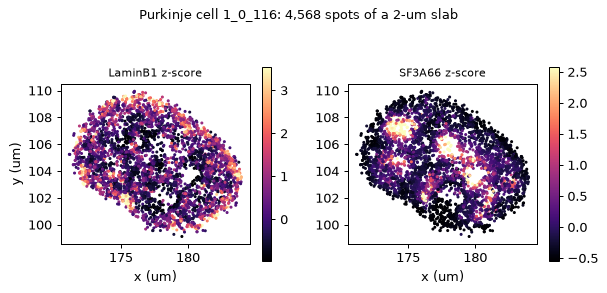

In [8]:
cell_id = cd.cells.index[cd.cells["cell_type"] == "Purkinje"][0]
one = cd.get_cell(cell_id)
mid = np.abs(one.coords[:, 2] - np.median(one.coords[:, 2])) < 1.0      # a 2-um optical slab
fig, axes = plt.subplots(1, 2, figsize=(7, 3.3))
for ax, mark in zip(axes, ["LaminB1", "SF3A66"]):
    v = one.spot_tracks[mark].to_numpy()[mid]
    sc = ax.scatter(one.coords[mid, 0], one.coords[mid, 1], c=v, s=2, cmap="magma",
                    vmin=np.percentile(v, 2), vmax=np.percentile(v, 98))
    ax.set_aspect("equal"); ax.set_title(f"{mark} z-score", fontsize=9)
    ax.set_xlabel("x (um)"); fig.colorbar(sc, ax=ax, shrink=0.8)
axes[0].set_ylabel("y (um)")
fig.suptitle(f"Purkinje cell {cell_id}: {mid.sum():,} spots of a 2-um slab", fontsize=10)
plt.tight_layout(); plt.show()

### Cells, positions and embeddings (`cells`, `cellm`)

The clustering table gives each cell its leiden cluster, a cell type (through
`uns['leiden_to_cell_type']`), nuclear volume and centroid.  The centroid is stored in voxels
with the voxel size in its `uns['cell_spatial']` record, so `cell_positions(physical=True)`
returns µm in the frame of `coords` (one frame per FOV, `region` = `"{rep}_{fov}"`).  The
published RNA UMAP is `cellm['umap']`.

In [9]:
print(cd.cells["cell_type"].value_counts().to_dict())
pos = cd.cell_positions(physical=True)
print({k: pos.attrs["cell_spatial"][k] for k in ("unit", "voxel_size", "frame", "region_col", "status")})
spot_centre = pd.DataFrame(xyz, columns=list("xyz")).groupby(cell_of).median().loc[pos.index]
offset = np.linalg.norm(spot_centre.to_numpy() - pos[["x", "y", "z"]].to_numpy(), axis=1)
print(f"centroid vs median DNA-spot position: median {np.median(offset):.2f} um, max {offset.max():.2f} um")
print("cellm:", {k: v.shape for k, v in cd.cellm.items()})
cd.cells.head()

{'Granule': 22, 'Other': 9, 'Bergmann': 8, 'MLI1': 3, 'Purkinje': 3, 'MLI2+PLI': 2}
{'unit': 'um', 'voxel_size': [0.103, 0.103, 0.25], 'frame': 'fov', 'region_col': 'fov', 'status': 'measured'}


centroid vs median DNA-spot position: median 0.62 um, max 1.96 um
cellm: {'umap': (47, 2)}


,leiden,cell_type,fov,centroid_x,centroid_y,centroid_z,nuc_volume_um3,doublet,batch
cell_id,,,,,,,,,
1_0_72,0,Granule,1_0,1255.603,1677.512,13.784,117.001,0,1
1_0_104,0,Granule,1_0,1724.202,1535.181,14.662,120.823,0,1
1_0_123,0,Granule,1_0,876.227,1409.527,18.072,198.996,0,1
1_0_139,0,Granule,1_0,1823.625,1291.029,17.587,188.803,0,1
1_0_169,0,Granule,1_0,1635.217,1531.118,16.907,147.417,0,1


Per-cell summaries of the spot signals go to `cells` with `uchrom.emb.aggregate_tracks`
(here the mean z-score of each IF channel, as `if.<mark>` columns).

In [10]:
marks = [m for m in IF_COLUMNS if m in tracks.columns]
aggregate_tracks(cd, marks, prefix="if", stat="mean")
summary = cd.cells.groupby("cell_type")[["if.H3K27ac", "if.H3K9me3", "if.H3K27me3", "if.LaminB1", "if.SF3A66"]].mean()
summary.insert(0, "n_cells", cd.cells["cell_type"].value_counts())
summary.round(2)

,n_cells,if.H3K27ac,if.H3K9me3,if.H3K27me3,if.LaminB1,if.SF3A66
cell_type,,,,,,
Bergmann,8,0.37,0.38,0.26,0.35,0.12
Granule,22,0.16,0.25,0.22,0.19,0.07
MLI1,3,0.34,0.44,0.43,0.29,0.08
MLI2+PLI,2,0.18,0.31,0.29,0.26,0.08
Other,9,0.23,0.30,0.24,0.29,0.09
Purkinje,3,0.44,0.38,0.72,0.35,0.02


### Traces and the allele caveat (`traces`)

Homolog assignment is the weak point of this data.  The loader builds traces from the
highest-recall column `dbscan_ldp_nbr_allele` (the one the authors' notebooks use) and
records per-trace quality: `n_loci`, `n_duplicate_loci` (spots whose locus already occurs in
the trace — more than 0 means two homologs or stray spots were merged) and how well the other
two allele calls agree.  If your analysis needs one fibre per trace (distance maps, TAD /
loop calling), import with `allele_col="dbscan_ldp_allele"`: fewer spots, no duplicates.

In [11]:
tr = cd.traces
print(f"dbscan_ldp_nbr_allele: {cd.n_spots:,} spots, {cd.n_traces:,} traces, "
      f"{(tr['n_duplicate_loci'] > 0).mean():.0%} of traces observe some locus twice")
strict = read_seqfish_multiomics(SPOTS, locus_annotation=LOCI, cell_clustering=CLUSTERS,
                                 allele_col="dbscan_ldp_allele")
print(f"dbscan_ldp_allele    : {strict.n_spots:,} spots ({strict.n_spots / cd.n_spots:.0%}), "
      f"{strict.n_traces:,} traces, {(strict.traces['n_duplicate_loci'] > 0).mean():.0%} with a repeated locus")
tr.head()

dbscan_ldp_nbr_allele: 383,674 spots, 1,500 traces, 85% of traces observe some locus twice


dbscan_ldp_allele    : 212,770 spots (55%), 1,432 traces, 0% with a repeated locus


,allele,n_spots,n_loci,n_duplicate_loci,dbscan_allele_majority,dbscan_allele_agreement,dbscan_ldp_allele_majority,dbscan_ldp_allele_agreement
trace_id,,,,,,,,
1_0_270_chr10_a1,1,818,754,64,1,1.000000,-1,0.564792
1_0_270_chr5_a1,1,696,654,42,1,1.000000,-1,0.547414
1_0_270_chrX_a1,1,980,893,87,1,0.997959,1,0.548980
1_0_270_chr14_a1,1,641,604,37,1,1.000000,-1,0.533541
1_0_270_chr17_a1,1,540,500,40,1,1.000000,-1,0.711111


In [12]:
{k: v for k, v in cd.uns.items() if k != "cell_spatial"}

{'genome_assembly': 'mm10',
 'xyz_unit': 'um',
 'voxel_xy_nm': 103,
 'voxel_z_nm': 250,
 'source': 'Takei2025_cerebellum',
 'zenodo_record': '7693825',
 'leiden_to_cell_type': {'0': 'Granule',
  '1': 'Granule',
  '2': 'Bergmann',
  '4': 'MLI1',
  '6': 'Purkinje',
  '11': 'Purkinje',
  '7': 'MLI2+PLI'},
 'allele_col': 'dbscan_ldp_nbr_allele',
 'keep_unclustered': False}

## 4. Streaming import into a store

With `out=`, `read_seqfish_multiomics` reads the FOV files one at a time into a
`.chromdata.zarr` store, so memory holds one FOV (a full FOV CSV is 2–3 GB) instead of all
of them, and returns the store opened backed.  The store holds the same spots and signals as
the in-memory import.

In [13]:
t0 = time.perf_counter()
store = read_seqfish_multiomics(SPOTS, locus_annotation=LOCI, cell_clustering=CLUSTERS,
                                out=OUT / "takei2025_fov0_47cells.chromdata.zarr")
print(f"streamed in {time.perf_counter() - t0:.1f} s -> {type(store).__name__}")


def table(x):
    """Spots + coordinates + per-spot signals, in a canonical row order."""
    df = pd.concat([x.to_dataframe().reset_index(drop=True), x.spot_tracks.reset_index(drop=True)], axis=1)
    df["trace_id"] = df["trace_id"].astype(str); df["cell_id"] = df["cell_id"].astype(str)
    return df.sort_values(["trace_id", "start", "x", "y", "z"]).reset_index(drop=True)


pd.testing.assert_frame_equal(table(cd), table(store.to_memory()), check_categorical=False)
pd.testing.assert_frame_equal(cd.cells.drop(columns=[c for c in cd.cells if c.startswith("if.")]), store.cells)
print(f"streamed store == in-memory import: {store.n_spots:,} spots x {store.spot_tracks.shape[1]} signals, "
      f"{len(store.cells)} cells")

streamed in 7.5 s -> BackedChromData


streamed store == in-memory import: 383,674 spots x 62 signals, 47 cells


## 5. The whole replicate, opened backed

Replicate 1 has three FOVs: 1,799 cells and 10.9 million spots (2 GB as a store).  The public
U-Chrom atlas holds it as a store (built by `apps/atlas/recipes/build_takei2025_cerebellum.py`
from the Zenodo tarball), and `ds.atlas("takei2025_cerebellum")` opens it over HTTP, backed:
the small tables load at once, spots are read only when asked for — here the spots of one
Purkinje cell.  `uchrom.io.load_takei2025_cerebellum()` is the local alternative: it downloads
the 2.85 GB tarball and the RNA data from Zenodo, builds the store and the linked RNA AnnData in
the data directory, and returns the data **in memory** (≈10 GB).

opened in 1.83 s: 10,912,638 spots, 59,112 traces, 1,799 cells, 100,049 loci, 62 spot tracks
{'Granule': 1109, 'Other': 323, 'Bergmann': 192, 'MLI1': 90, 'Purkinje': 58, 'MLI2+PLI': 27}


get_cell: 4,225 spots + 62 signals read in 1.26 s


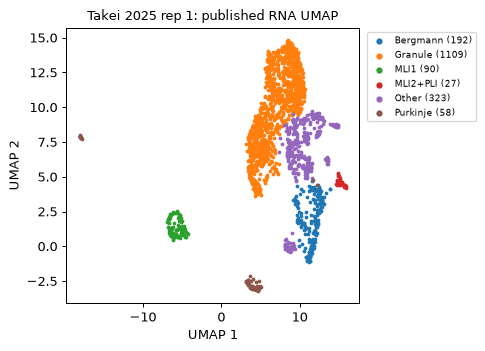

In [14]:
t0 = time.perf_counter()
rep1 = ds.atlas("takei2025_cerebellum")
print(f"opened in {time.perf_counter() - t0:.2f} s: {rep1.n_spots:,} spots, {rep1.n_traces:,} traces, "
      f"{rep1.n_cells:,} cells, {rep1.n_bins:,} loci, {len(rep1.spot_tracks.columns)} spot tracks")
print(rep1.cells["cell_type"].value_counts().to_dict())

t0 = time.perf_counter()
purk = rep1.get_cell(rep1.cells.index[rep1.cells["cell_type"] == "Purkinje"][0])
print(f"get_cell: {purk.n_spots:,} spots + {purk.spot_tracks.shape[1]} signals read in "
      f"{time.perf_counter() - t0:.2f} s")

umap, ctype = rep1.cellm["umap"], rep1.cells["cell_type"].astype(str).to_numpy()
fig, ax = plt.subplots(figsize=(5.5, 4))
for t in sorted(set(ctype)):
    m = ctype == t
    ax.scatter(umap[m, 0], umap[m, 1], s=4, label=f"{t} ({m.sum()})")
ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2"); ax.set_title("Takei 2025 rep 1: published RNA UMAP", fontsize=10)
ax.legend(fontsize=7, markerscale=2, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()

## Next steps

- `chromdata_basics.ipynb` — the container itself (backed stores, `iter_cells`, results).
- `import_fofct.ipynb` / `import_pyhim_ecsv.ipynb` — other imaging formats.
- Structure calling on imaging traces: `tad_calling.ipynb`, `loop_calling.ipynb`,
  `compartment.ipynb` (prefer `allele_col="dbscan_ldp_allele"` here).
- `takei2025_auto_discovery.ipynb` — LLM-driven hypothesis generation on this dataset.
- Browse the store: `python -m uchrom_browser tutorials/_out/takei2025_fov0_47cells.chromdata.zarr`.